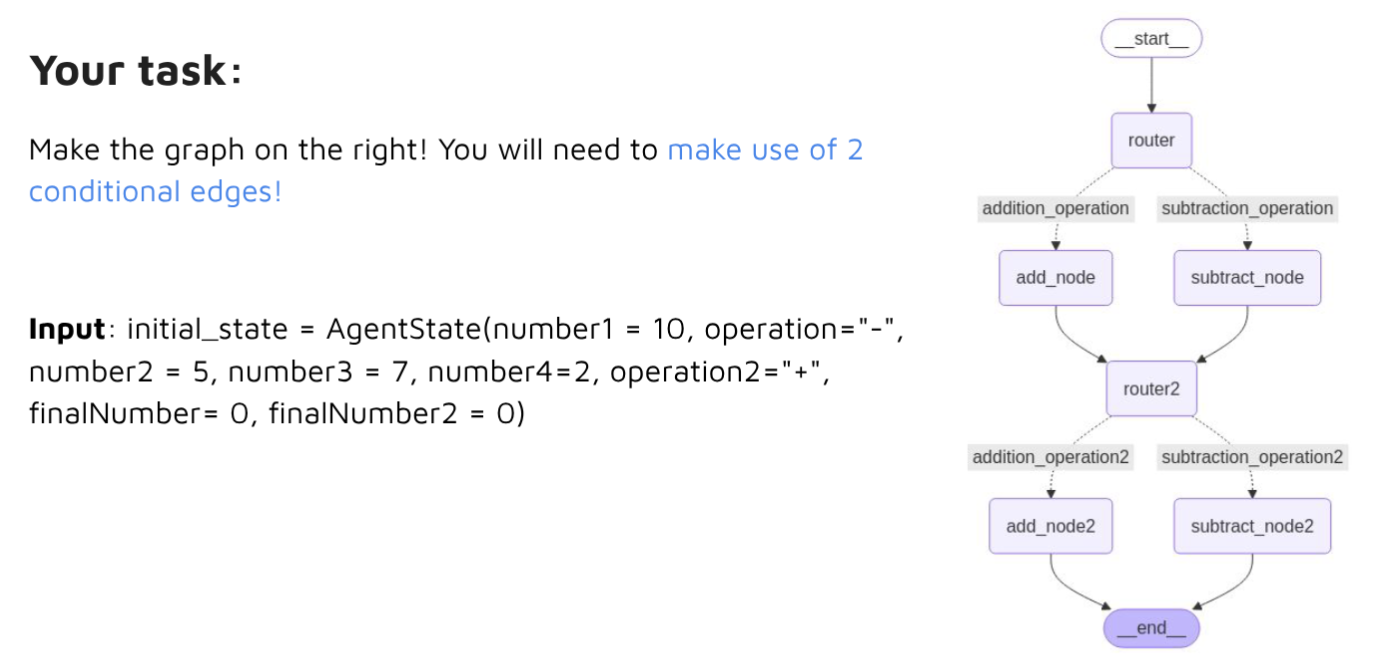

In [5]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [3]:
class AgentState(TypedDict):
    number1: int
    operation: str
    number2: int
    number3: int
    number4: int
    operation2: str
    finalNumber: int
    finalNumber2: int

In [4]:
def addition1(state: AgentState) -> AgentState:
    """this function adds 2 numbers"""

    state['finalNumber'] = state['number1'] + state['number2']
    return state

def addition2(state: AgentState) -> AgentState:
    """this function adds 2 numbers"""

    state['finalNumber2'] = state['number3'] + state['number4']
    return state

def subtraction1(state: AgentState) -> AgentState:
    """this function subtracts 2 numbers"""

    state['finalNumber'] = state['number1'] - state['number2']
    return state

def subtraction2(state: AgentState) -> AgentState:
    """this function subtracts 2 numbers"""

    state['finalNumber2'] = state['number3'] - state['number4']
    return state

def decide_first_node(state: AgentState) -> AgentState:
    """this node decides which operation to run"""

    if state['operation'] == '+':
        return 'addition_operation'
    elif state['operation'] == '-':
        return 'subtraction_operation'

def decide_second_node(state: AgentState) -> AgentState:
    """this node decides which operation to run"""
    if state['operation2'] == '+':
        return 'addition_operation2'
    elif state['operation2'] == '-':
        return 'subtraction_operation2'

In [6]:
graph = StateGraph(AgentState)

graph.add_node(node='router', action=lambda state: state)
graph.add_node(node='router2', action=lambda state: state)
graph.add_node(node='add_node', action=addition1)
graph.add_node(node='add_node2', action=addition2)
graph.add_node(node='subtract_node', action=subtraction1)
graph.add_node(node='subtract_node2', action=subtraction2)

graph.add_edge(START, 'router')

graph.add_conditional_edges(
    'router',
    decide_first_node,
    {
        'addition_operation': 'add_node',
        'subtraction_operation': 'subtract_node'
    }
)

graph.add_edge('add_node', 'router2')
graph.add_edge('subtract_node', 'router2')

graph.add_conditional_edges(
    'router2',
    decide_second_node,
    {
        'addition_operation2': 'add_node2',
        'subtraction_operation2': 'subtract_node2'
    }
)

graph.add_edge('add_node2', END)
graph.add_edge('subtract_node2', END)

app = graph.compile()

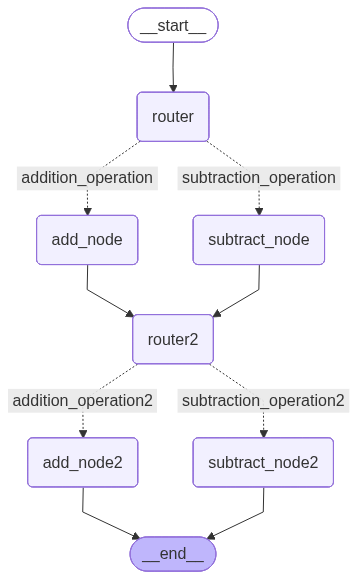

In [7]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

In [8]:
initial_state1 = AgentState(
    number1=10,
    operation='-',
    number2=5,
    number3=7,
    operation2='+',
    number4=2,
    finalNumber=0,
    finalNumber2=0
)

In [9]:
print(app.invoke(initial_state1))

{'number1': 10, 'operation': '-', 'number2': 5, 'number3': 7, 'number4': 2, 'operation2': '+', 'finalNumber': 5, 'finalNumber2': 9}
